# Evaluación Parcial 3: pipeline integrado y comparación MLP vs CNN para patologías en tomate

- Asignatura: TLY1102 Técnicas Avanzadas de Machine Learning I
- Sección: 001D
- Integrantes: Matías Gutiérrez, David Larenas, Victor Mena
- Fecha: noviembre de 2026

Este notebook documenta el pipeline integrado de la EP3. Reutiliza el conjunto de datos y la partición de la EP2, agrega regularización, búsqueda de hiperparámetros, auditoría de sesgos y explicabilidad. Comparamos una MLP optimizada con una CNN final y justificamos la arquitectura recomendada.

## 1. Problema, objetivos y KPIs

Buscamos apoyar la priorización de hojas de tomate con síntomas. No reemplazamos al especialista. Comparamos una MLP y una CNN con el mismo split y las mismas condiciones.

El objetivo general es construir y comparar las dos arquitecturas con un pipeline reproducible, auditoría de sesgos y explicabilidad. Los objetivos específicos son reutilizar el split de la EP2, implementar las etapas en funciones, medir la regularización, buscar hiperparámetros y comparar las dos arquitecturas.

- **Exactitud:** meta 90%, CNN 94,44%, MLP 69,23%.
- **F1 macro:** meta 90%, CNN 93,00%, MLP 65,14%.
- **ROC-AUC:** meta 95%, CNN 99,73%, MLP 96,35%.
- **Brecha train-test:** meta 10 puntos, CNN 5,4, MLP 15,7.

## 2. Datos: carga, verificación y análisis exploratorio

Trabajamos con el subconjunto de tomate de PlantVillage usado en la EP2. Son 16.011 imágenes de 256x256 en diez clases. Mantener el mismo dataset y la misma partición permite comparar los resultados con la evaluación anterior.

La partición está fijada en data/split.csv con 12.808 imágenes de entrenamiento, 1.601 de validación y 1.602 de test. La estratificación conserva la proporción de clases en los tres conjuntos. El test no se usa para elegir hiperparámetros.

In [1]:
import gc
import hashlib
import json
import os
import random
import time
from pathlib import Path

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from lime import lime_image
from skimage.segmentation import mark_boundaries
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

tf.get_logger().setLevel('ERROR')

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 40
PACIENCIA = 5
AUTOTUNE = tf.data.AUTOTUNE


RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = RAIZ / 'data'
MODELS_DIR = RAIZ / 'models'
IMAGES_DIR = RAIZ / 'images'
HISTORY_DIR = MODELS_DIR / 'historial'
REPORTS_DIR = MODELS_DIR / 'reportes'
for directorio in (DATA_DIR, MODELS_DIR, IMAGES_DIR, HISTORY_DIR, REPORTS_DIR):
    directorio.mkdir(parents=True, exist_ok=True)

zip_datos = RAIZ / 'PlantVillage Dataset.zip'
if not (DATA_DIR / 'PlantVillage').exists() and zip_datos.exists():
    os.system(f'unzip -o -q "{zip_datos}" -d "{DATA_DIR}"')

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', palette='deep')

print('Raíz del proyecto:', RAIZ)
print('TensorFlow:', tf.__version__)


In [2]:
def cargar_datos(data_root=DATA_DIR / 'PlantVillage', split_path=DATA_DIR / 'split.csv'):
    df = pd.read_csv(split_path)
    clases = json.loads((DATA_DIR / 'class_names.json').read_text())
    df['y'] = df['label'].map({clase: i for i, clase in enumerate(clases)})
    df['abs_path'] = df['filepath'].map(lambda ruta: str(data_root / ruta))
    return df, clases

df, clases = cargar_datos()
resumen = df.pivot_table(index='label', columns='split', values='filepath', aggfunc='count', fill_value=0).reindex(clases)
resumen = resumen[['train', 'val', 'test']]
resumen['total'] = resumen.sum(axis=1)
display(df.head())
display(resumen)


Imágenes: 16011
split
test      1602
train    12808
val       1601
dtype: int64


,filepath,label,split,y,abs_path
0,Tomato_Bacterial_spot/00416648-be6e-4bd4-bc8d-...,Tomato_Bacterial_spot,train,0,/mnt/NeuralVault/ava_blackboard/TECNICAS AVANZ...
1,Tomato_Bacterial_spot/0045ba29-ed1b-43b4-afde-...,Tomato_Bacterial_spot,test,0,/mnt/NeuralVault/ava_blackboard/TECNICAS AVANZ...
2,Tomato_Bacterial_spot/00639d29-2d1a-4fcf-9bd3-...,Tomato_Bacterial_spot,train,0,/mnt/NeuralVault/ava_blackboard/TECNICAS AVANZ...
3,Tomato_Bacterial_spot/00728f4d-83a0-49f1-87f8-...,Tomato_Bacterial_spot,train,0,/mnt/NeuralVault/ava_blackboard/TECNICAS AVANZ...
4,Tomato_Bacterial_spot/00a7c269-3476-4d25-b744-...,Tomato_Bacterial_spot,train,0,/mnt/NeuralVault/ava_blackboard/TECNICAS AVANZ...


La carga lee split.csv y class_names.json. Conservamos la partición de la EP2 y el orden de clases en todas las corridas.

In [3]:
def cargar_imagen(ruta, etiqueta):
    imagen = tf.io.read_file(ruta)
    imagen = tf.io.decode_image(imagen, channels=3, expand_animations=False)
    imagen = tf.image.resize(imagen, IMG_SIZE)
    return tf.cast(imagen, tf.float32), etiqueta


def crear_dataset(df, split, entrenamiento=False, batch_size=BATCH_SIZE, transformacion=None):
    datos = df[df['split'] == split]
    ds = tf.data.Dataset.from_tensor_slices((datos['abs_path'].values, datos['y'].values))
    ds = ds.map(cargar_imagen, num_parallel_calls=AUTOTUNE).cache()
    if entrenamiento:
        ds = ds.shuffle(len(datos), seed=SEED, reshuffle_each_iteration=True)
    if transformacion is not None:
        ds = ds.map(lambda x, y: (transformacion(x), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)


train_ds = crear_dataset(df, 'train', entrenamiento=True)
val_ds = crear_dataset(df, 'val')
test_ds = crear_dataset(df, 'test')
print('Lotes de entrenamiento:', len(train_ds))
print('Lotes de validación:', len(val_ds))
print('Lotes de test:', len(test_ds))
for x_batch, y_batch in train_ds.take(1):
    print('Forma del lote:', x_batch.shape, y_batch.shape)

Lotes de entrenamiento: 401
Lotes de validación: 51
Lotes de test: 51


Forma del lote: (32, 128, 128, 3) (32,)


La función crear_dataset decodifica las imágenes, las redimensiona a 128x128 y las mantiene en memoria con cache. El entrenamiento se mezcla en cada época. La validación y el test conservan el orden, lo que permite alinear las predicciones con las etiquetas.

### 2.1 Balance de clases

El desbalance es visible. La clase Tomato Yellow Leaf Curl Virus tiene 2.566 imágenes de entrenamiento y Tomato mosaic virus tiene 298. La razón es cercana a 8,6 a 1. Esta diferencia es la primera fuente de sesgo de entrada y justifica mirar el recall por clase, no solo la accuracy global.

In [4]:
def nombre_corto(clase):
    return clase.replace('Tomato__', '').replace('Tomato_', '').replace('_', ' ').strip()


resumen = df.pivot_table(index='label', columns='split', values='filepath', aggfunc='count', fill_value=0).reindex(clases)
resumen = resumen[['train', 'val', 'test']]
resumen['total'] = resumen.sum(axis=1)
resumen['proporcion'] = resumen['total'] / resumen['total'].sum()
display(resumen)
print('Razón entre la clase mayoritaria y la minoritaria:', round(resumen['total'].max() / resumen['total'].min(), 2))

split,train,val,test,total,proporcion
label,,,,,
Tomato_Bacterial_spot,1701,213,213,2127,0.132846
Tomato_Early_blight,800,100,100,1000,0.062457
Tomato_Late_blight,1527,191,191,1909,0.119231
Tomato_Leaf_Mold,762,95,95,952,0.059459
Tomato_Septoria_leaf_spot,1417,177,177,1771,0.110611
Tomato_Spider_mites_Two_spotted_spider_mite,1341,167,168,1676,0.104678
Tomato__Target_Spot,1123,140,141,1404,0.087690
Tomato__Tomato_YellowLeaf__Curl_Virus,2566,321,321,3208,0.200362
Tomato__Tomato_mosaic_virus,298,38,37,373,0.023296


Razón entre la clase mayoritaria y la minoritaria: 8.6


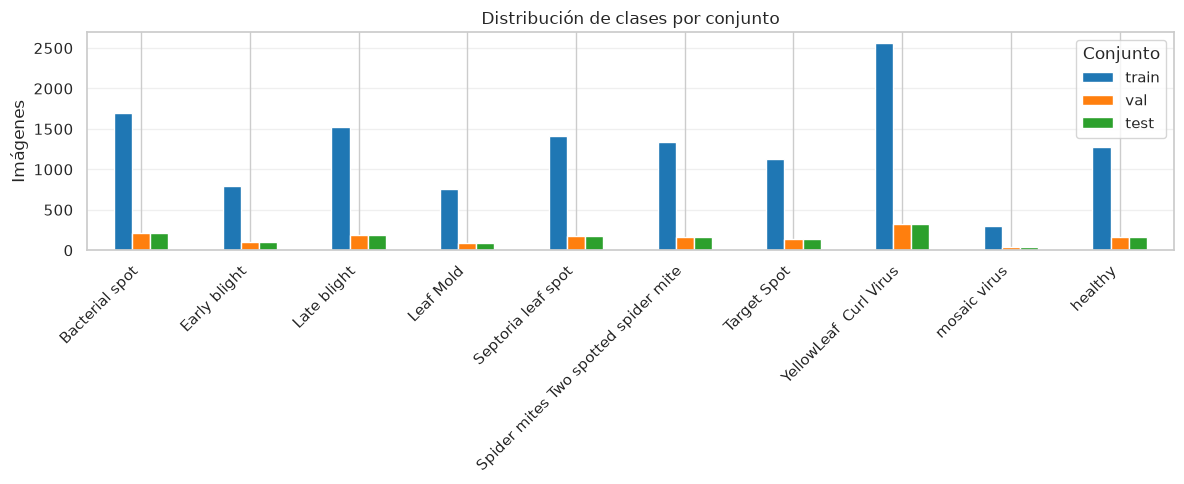

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
resumen[['train', 'val', 'test']].plot(kind='bar', ax=ax, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
ax.set_title('Distribución de clases por conjunto')
ax.set_xlabel('')
ax.set_ylabel('Imágenes')
ax.set_xticklabels([nombre_corto(clase) for clase in resumen.index], rotation=45, ha='right')
ax.legend(title='Conjunto')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'balance_clases.png', dpi=150)
plt.show()

### 2.2 Muestras y propiedades

Las imágenes son de laboratorio, con una hoja centrada y un fondo relativamente uniforme. Esa uniformidad ayuda al modelo, pero no representa una fotografía de campo. La limitación se retoma en la auditoría y en las conclusiones.

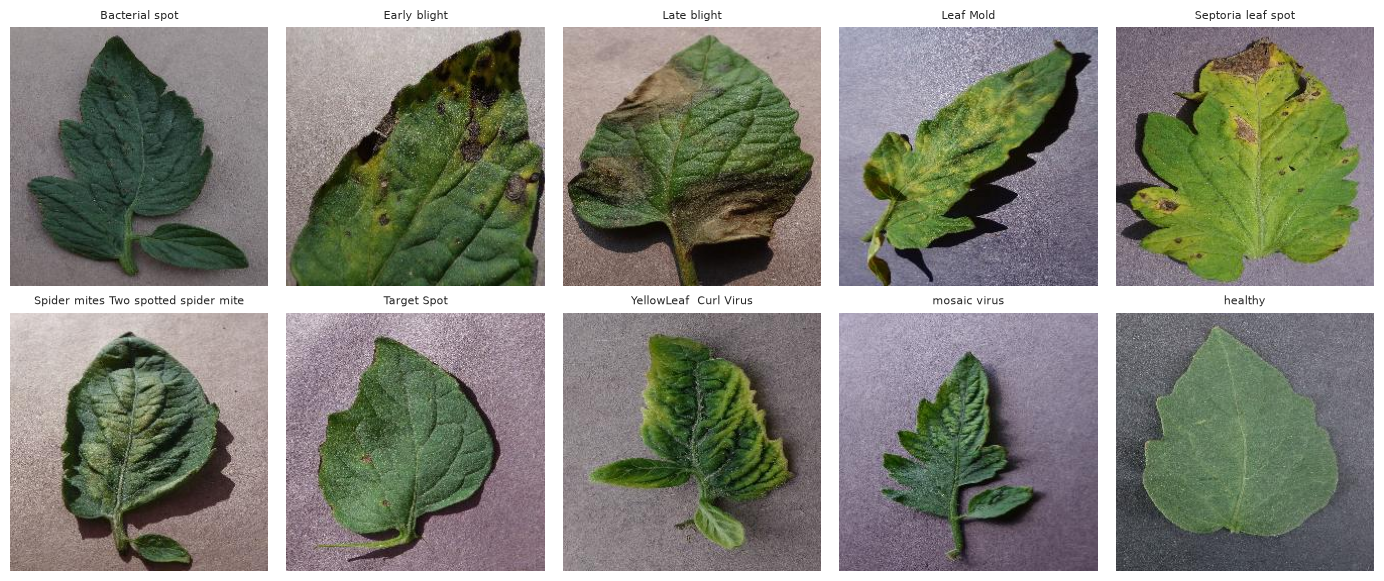

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, clase in zip(axes.ravel(), clases):
    fila = df[(df['label'] == clase) & (df['split'] == 'train')].iloc[0]
    ax.imshow(plt.imread(fila['abs_path']))
    ax.set_title(nombre_corto(clase), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'muestras_clases.png', dpi=150)
plt.show()

## 3. Preprocesamiento y aumento de datos

El preprocesamiento es mínimo para no introducir información externa. Redimensionamos a 128x128, mantenemos tres canales y normalizamos con la capa Rescaling, que divide cada píxel entre 255. El aumento se aplica solo durante el entrenamiento.

Elegimos transformaciones que no cambian el significado de la hoja:

- **Volteo horizontal:** una hoja girada sigue siendo la misma hoja.
- **Rotación de 0,08:** equivale a unos 29 grados.
- **Zoom de 0,10:** simula cambios de distancia.
- **Traslación de 0,08:** mueve la hoja dentro del encuadre.
- **Contraste de 0,10:** simula cambios de iluminación.

No usamos volteo vertical porque una hoja invertida no es una variación natural. No usamos recortes agresivos porque podrían eliminar lesiones pequeñas.

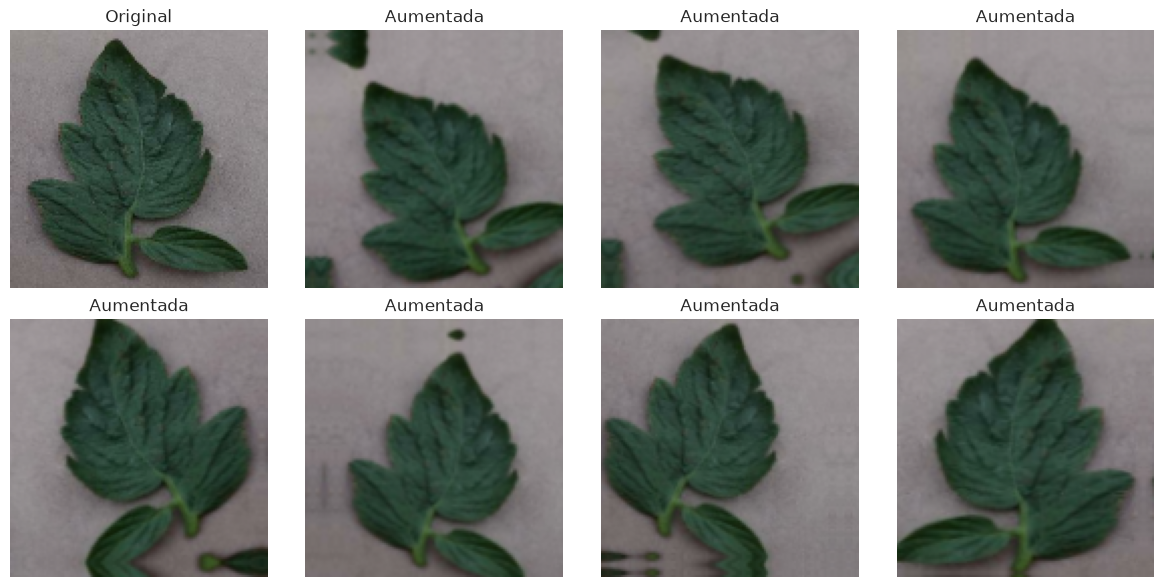

In [7]:
def crear_aumento():
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip('horizontal'),
        tf.keras.layers.RandomRotation(0.08),
        tf.keras.layers.RandomZoom(0.10),
        tf.keras.layers.RandomTranslation(0.08, 0.08),
        tf.keras.layers.RandomContrast(0.10),
    ], name='aumento_datos')


data_augmentation = crear_aumento()
fila = df[df['split'] == 'train'].iloc[0]
imagen, _ = cargar_imagen(fila['abs_path'], fila['y'])
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes[0, 0].imshow(imagen.numpy().astype('uint8'))
axes[0, 0].set_title('Original')
axes[0, 0].axis('off')
for ax in axes.ravel()[1:]:
    aumentada = data_augmentation(tf.expand_dims(imagen, 0), training=True)[0].numpy()
    ax.imshow(np.clip(aumentada, 0, 255).astype('uint8'))
    ax.set_title('Aumentada')
    ax.axis('off')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'aumento_datos.png', dpi=150)
plt.show()

El aumento genera copias plausibles y no reemplaza la falta de imágenes de campo. Su efecto se mide en la ablación. La capa se crea de nuevo para cada modelo para evitar que el estado de una corrida afecte a la siguiente.

## 4. Funciones del pipeline

Organizamos el pipeline en funciones reutilizables. Cada una cubre una etapa.

- **Carga:** cargar_datos, cargar_imagen y crear_dataset.
- **Aumento:** crear_aumento.
- **Modelo:** construir_modelo.
- **Entrenamiento:** entrenar_modelo y entrenar_final.
- **Evaluación:** evaluar_metricas y graficar_curvas.
- **Búsqueda:** optimizar_modelo.
- **Explicabilidad:** gradcam y explicar_lime.
- **Auditoría:** medir_inferencia y prueba_estres.

In [8]:
def construir_modelo(tipo, filtros=(32, 64, 128), neuronas=128, capas_mlp=(512, 256, 128), dropout_conv=0.2, dropout_dense=0.3, l2=1e-4, usar_bn=True, usar_aumento=True, learning_rate=1e-4):
    regularizador = tf.keras.regularizers.l2(l2) if l2 and l2 > 0 else None
    capas = [tf.keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)), tf.keras.layers.Rescaling(1./255)]
    if usar_aumento:
        capas.append(crear_aumento())
    if tipo == 'mlp':
        capas.append(tf.keras.layers.Flatten())
        for unidades in capas_mlp:
            capas.append(tf.keras.layers.Dense(unidades, kernel_initializer='he_normal', kernel_regularizer=regularizador))
            if usar_bn:
                capas.append(tf.keras.layers.BatchNormalization())
            capas.append(tf.keras.layers.Activation('relu'))
            capas.append(tf.keras.layers.Dropout(dropout_dense))
        capas.append(tf.keras.layers.Dense(len(clases), activation='softmax'))
    elif tipo == 'cnn':
        for i, filtros_capa in enumerate(filtros, start=1):
            capas.append(tf.keras.layers.Conv2D(filtros_capa, (3, 3), padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizador, name=f'conv_{i}'))
            if usar_bn:
                capas.append(tf.keras.layers.BatchNormalization())
            capas.append(tf.keras.layers.Activation('relu', name=f'conv_{i}_relu'))
            capas.append(tf.keras.layers.MaxPooling2D((2, 2)))
            capas.append(tf.keras.layers.Dropout(dropout_conv))
        capas.append(tf.keras.layers.Flatten())
        capas.append(tf.keras.layers.Dense(neuronas, kernel_initializer='he_normal', kernel_regularizer=regularizador))
        if usar_bn:
            capas.append(tf.keras.layers.BatchNormalization())
        capas.append(tf.keras.layers.Activation('relu'))
        capas.append(tf.keras.layers.Dropout(dropout_dense))
        capas.append(tf.keras.layers.Dense(len(clases), activation='softmax'))
    modelo = tf.keras.Sequential(capas, name=f'{tipo}_ep3')
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return modelo


modelo_base = construir_modelo('cnn')
modelo_base.summary()
del modelo_base
tf.keras.backend.clear_session()

Model: "cnn_ep3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_datos (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1_relu (Activation)        │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2_relu (Activation)        │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3_relu (Activation)        │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,29

 Total params: 4,290,378 (16.37 MB)

 Trainable params: 4,289,674 (16.36 MB)

 Non-trainable params: 704 (2.75 KB)

La CNN usa tres bloques de convolución con 32, 64 y 128 filtros, kernel 3x3, padding same, inicialización He y Batch Normalization. Cada bloque termina en MaxPooling y Dropout. La cabeza tiene una capa densa de 128 unidades y una salida softmax de diez clases.

La MLP aplana la imagen y usa tres capas densas. La configuración final quedó con 256, 128 y 64 unidades, con BatchNorm, Dropout y L2. Tiene más parámetros que la CNN, pero no aprovecha la estructura espacial. Esa diferencia es la hipótesis central de la comparación.

In [9]:
def entrenar_modelo(modelo, train_ds, val_ds, nombre, epochs=EPOCHS, patience=PACIENCIA, verbose=0):
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)]
    inicio = time.time()
    historia = modelo.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=verbose, shuffle=False)
    tiempo = time.time() - inicio
    pd.DataFrame(historia.history).to_csv(HISTORY_DIR / f'{nombre}.csv', index=False)
    return historia, tiempo


def graficar_curvas(historia, nombre):
    datos = historia.history if hasattr(historia, 'history') else historia
    epocas = range(1, len(datos['loss']) + 1)
    mejor = int(np.argmin(datos['val_loss'])) + 1
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(epocas, datos['loss'], label='Entrenamiento', color='#1f77b4')
    ax1.plot(epocas, datos['val_loss'], label='Validación', color='#ff7f0e')
    ax1.axvline(mejor, color='#2ca02c', linestyle='--', label=f'Mejor época: {mejor}')
    ax1.axvspan(mejor, len(datos['loss']), color='#2ca02c', alpha=0.08, label='Ventana de paciencia')
    ax1.set_title('Pérdida')
    ax1.set_xlabel('Época')
    ax1.set_ylabel('Pérdida')
    ax1.legend()
    ax1.grid(alpha=0.3)
    ax2.plot(epocas, datos['accuracy'], label='Entrenamiento', color='#1f77b4')
    ax2.plot(epocas, datos['val_accuracy'], label='Validación', color='#ff7f0e')
    ax2.axvline(mejor, color='#2ca02c', linestyle='--', label=f'Mejor época: {mejor}')
    ax2.axvspan(mejor, len(datos['loss']), color='#2ca02c', alpha=0.08, label='Ventana de paciencia')
    ax2.set_title('Accuracy')
    ax2.set_xlabel('Época')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(alpha=0.3)
    fig.suptitle(f'{nombre} - mejor época {mejor}', y=1.02)
    plt.tight_layout()
    plt.savefig(IMAGES_DIR / f'curvas_{nombre.lower().replace(" ", "_")}.png', dpi=150, bbox_inches='tight')
    plt.show()


In [10]:
def evaluar_metricas(modelo, ds, nombre, guardar=True, graficar=True):
    y_true = np.concatenate([y_batch.numpy() for _, y_batch in ds], axis=0)
    y_prob = modelo.predict(ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    metricas = {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'precision_weighted': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'f1_weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
    }
    metricas['roc_auc'] = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
    reporte = classification_report(y_true, y_pred, labels=np.arange(len(clases)), target_names=clases, output_dict=True, zero_division=0)
    reporte_df = pd.DataFrame(reporte).transpose()
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(clases)))
    if graficar:
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clases, yticklabels=clases)
        plt.xlabel('Predicción')
        plt.ylabel('Clase real')
        plt.title(f'Matriz de confusión - {nombre}')
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.savefig(IMAGES_DIR / f'matriz_{nombre.lower().replace(" ", "_")}.png', dpi=150, bbox_inches='tight')
        plt.show()
    if guardar:
        slug = nombre.lower().replace(' ', '_')
        (REPORTS_DIR / f'reporte_{slug}.txt').write_text(classification_report(y_true, y_pred, labels=np.arange(len(clases)), target_names=clases, zero_division=0))
        reporte_df.to_csv(REPORTS_DIR / f'reporte_{slug}.csv')
    return {
        'metricas': metricas,
        'y_true': y_true,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'cm': cm,
        'reporte_df': reporte_df,
    }

In [11]:
def optimizar_modelo(df, configuraciones, nombre_bloque, epochs=EPOCHS, verbose=0):
    resultados = []
    for i, config in enumerate(configuraciones, start=1):
        tf.keras.utils.set_random_seed(config.get('seed', SEED))
        train_ds = crear_dataset(df, 'train', entrenamiento=True, batch_size=config.get('batch_size', BATCH_SIZE))
        val_ds = crear_dataset(df, 'val', batch_size=config.get('batch_size', BATCH_SIZE))
        parametros = {k: v for k, v in config.items() if k not in {'nombre', 'batch_size', 'epochs', 'seed'}}
        modelo = construir_modelo(**parametros)
        historia, tiempo = entrenar_modelo(modelo, train_ds, val_ds, config['nombre'], epochs=config.get('epochs', epochs), verbose=verbose)
        evaluacion = evaluar_metricas(modelo, val_ds, config['nombre'], guardar=False, graficar=False)
        fila = {
            'bloque': nombre_bloque,
            'experimento': config['nombre'],
            'tipo': config['tipo'],
            'filtros': '-'.join(map(str, config.get('filtros', ()))),
            'neuronas': config.get('neuronas', 128),
            'dropout_conv': config.get('dropout_conv', 0.0),
            'dropout_dense': config.get('dropout_dense', 0.0),
            'l2': config.get('l2', 0.0),
            'usar_bn': config.get('usar_bn', False),
            'usar_aumento': config.get('usar_aumento', False),
            'learning_rate': config.get('learning_rate', 1e-4),
            'batch_size': config.get('batch_size', BATCH_SIZE),
            'accuracy_train': historia.history['accuracy'][-1],
            'accuracy_val': evaluacion['metricas']['accuracy'],
            'f1_macro_val': evaluacion['metricas']['f1_macro'],
            'brecha_val': historia.history['accuracy'][-1] - evaluacion['metricas']['accuracy'],
            'parametros': modelo.count_params(),
            'epocas': len(historia.history['loss']),
            'tiempo_s': tiempo,
        }
        resultados.append(fila)
        print(f"[{i}/{len(configuraciones)}] {config['nombre']}: F1 macro val {fila['f1_macro_val']:.4f}, accuracy val {fila['accuracy_val']:.4f}, {fila['epocas']} épocas, {tiempo:.1f} s")
        del modelo
        tf.keras.backend.clear_session()
        gc.collect()
    resultados_df = pd.DataFrame(resultados)
    resultados_df.to_csv(MODELS_DIR / f'experimentos_{nombre_bloque}.csv', index=False)
    mejor = resultados_df.sort_values('f1_macro_val', ascending=False).iloc[0]
    mejor_config = next(c for c in configuraciones if c['nombre'] == mejor['experimento'])
    return resultados_df, mejor_config


In [12]:
def entrenar_final(datos, config, nombre, semillas, archivo_modelo):
    resultados = []
    ultima_evaluacion = None
    ultimo_modelo = None
    for semilla in semillas:
        tf.keras.utils.set_random_seed(semilla)
        train_ds = crear_dataset(datos, 'train', entrenamiento=True, batch_size=config.get('batch_size', BATCH_SIZE))
        val_ds = crear_dataset(datos, 'val', batch_size=config.get('batch_size', BATCH_SIZE))
        test_ds = crear_dataset(datos, 'test', batch_size=config.get('batch_size', BATCH_SIZE))
        parametros = {k: v for k, v in config.items() if k not in {'nombre', 'batch_size', 'epochs', 'seed'}}
        modelo = construir_modelo(**parametros)
        nombre_corrida = f'{nombre}_semilla_{semilla}'
        historia, tiempo = entrenar_modelo(modelo, train_ds, val_ds, nombre_corrida, epochs=config.get('epochs', EPOCHS), verbose=0)
        evaluacion = evaluar_metricas(modelo, test_ds, nombre_corrida, guardar=(semilla == semillas[0]), graficar=(semilla == semillas[0]))
        evaluacion_val = evaluar_metricas(modelo, val_ds, f'{nombre_corrida}_val', guardar=False, graficar=False)
        if semilla == semillas[0]:
            graficar_curvas(historia, nombre_corrida)
            modelo.optimizer = None
            modelo.save(MODELS_DIR / archivo_modelo)
            ultima_evaluacion = evaluacion
            ultimo_modelo = modelo
        resultados.append({
            'modelo': nombre,
            'semilla': semilla,
            'tipo': config.get('tipo'),
            'filtros': '-'.join(map(str, config.get('filtros', ()))),
            'neuronas': config.get('neuronas', 128),
            'dropout_conv': config.get('dropout_conv', 0.0),
            'dropout_dense': config.get('dropout_dense', 0.0),
            'l2': config.get('l2', 0.0),
            'usar_bn': config.get('usar_bn', False),
            'usar_aumento': config.get('usar_aumento', False),
            'learning_rate': config.get('learning_rate', 1e-4),
            'batch_size': config.get('batch_size', BATCH_SIZE),
            'accuracy_train': historia.history['accuracy'][-1],
            'accuracy_val': evaluacion_val['metricas']['accuracy'],
            'f1_macro_val': evaluacion_val['metricas']['f1_macro'],
            'accuracy': evaluacion['metricas']['accuracy'],
            'balanced_accuracy': evaluacion['metricas']['balanced_accuracy'],
            'f1_macro': evaluacion['metricas']['f1_macro'],
            'f1_weighted': evaluacion['metricas']['f1_weighted'],
            'roc_auc': evaluacion['metricas']['roc_auc'],
            'brecha_test': historia.history['accuracy'][-1] - evaluacion['metricas']['accuracy'],
            'parametros': modelo.count_params(),
            'epocas': len(historia.history['loss']),
            'tiempo_s': tiempo,
        })
        print(f'{nombre} semilla {semilla}: accuracy {evaluacion["metricas"]["accuracy"]:.4f}, F1 macro {evaluacion["metricas"]["f1_macro"]:.4f}, {len(historia.history["loss"])} épocas, {tiempo:.1f} s')
        if semilla != semillas[0]:
            del modelo
        tf.keras.backend.clear_session()
    return pd.DataFrame(resultados), ultima_evaluacion, ultimo_modelo

In [13]:
def gradcam(modelo, imagen, clase_idx, capa='conv_3_relu'):
    grad_model = tf.keras.Model(inputs=modelo.inputs[0], outputs=[modelo.get_layer(capa).output, modelo.outputs[0]])
    with tf.GradientTape() as tape:
        conv_outputs, predicciones = grad_model(imagen)
        class_channel = predicciones[:, clase_idx]
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_outputs[0] * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def superponer_gradcam(imagen, heatmap):
    heatmap = tf.image.resize(heatmap[..., None], IMG_SIZE).numpy().squeeze()
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    jet = plt.cm.jet(heatmap)[..., :3]
    return np.clip(imagen / 255.0 * 0.55 + jet * 0.45, 0, 1)


def explicar_lime(modelo, imagen, num_samples=300):
    explainer = lime_image.LimeImageExplainer()
    explicacion = explainer.explain_instance(
        np.asarray(imagen[0]).astype('uint8'),
        modelo.predict,
        top_labels=1,
        hide_color=0,
        num_samples=num_samples,
    )
    temp, mask = explicacion.get_image_and_mask(
        explicacion.top_labels[0],
        positive_only=True,
        num_features=5,
        hide_rest=False,
    )
    return mark_boundaries(temp / 255.0, mask), explicacion


def medir_inferencia(modelo, ds, repeticiones=3):
    for x_batch, _ in ds.take(1):
        modelo.predict(x_batch, verbose=0)
        tiempos = []
        for _ in range(repeticiones):
            inicio = time.time()
            modelo.predict(x_batch, verbose=0)
            tiempos.append((time.time() - inicio) / len(x_batch) * 1000)
    return float(np.mean(tiempos))


def ajustar_brillo(x, delta):
    return tf.clip_by_value(x + delta, 0.0, 255.0)


def ajustar_contraste(x, factor):
    return tf.clip_by_value((x / 255.0 - 0.5) * factor + 0.5, 0.0, 1.0) * 255.0


def prueba_estres(modelo, df, nombre):
    transformaciones = {
        'brillo_bajo': lambda x: ajustar_brillo(x, -30.0),
        'brillo_alto': lambda x: ajustar_brillo(x, 30.0),
        'contraste_bajo': lambda x: ajustar_contraste(x, 0.7),
        'contraste_alto': lambda x: ajustar_contraste(x, 1.3),
    }
    filas = []
    for nombre_transformacion, transformacion in transformaciones.items():
        ds = crear_dataset(df, 'test', transformacion=transformacion)
        evaluacion = evaluar_metricas(modelo, ds, f'estres_{nombre}_{nombre_transformacion}', guardar=False, graficar=False)
        filas.append({
            'transformacion': nombre_transformacion,
            'accuracy': evaluacion['metricas']['accuracy'],
            'f1_macro': evaluacion['metricas']['f1_macro'],
        })
    return pd.DataFrame(filas)

Las funciones de entrenamiento y evaluación comparten la misma partición, la misma semilla y el mismo preprocesamiento. La búsqueda evalúa siempre en validación. El test se reserva para la evaluación final y para la auditoría. La parada temprana monitorea la pérdida de validación y restaura los mejores pesos.

## 6. Ablación de regularización

La ablación mide el efecto de cada técnica por separado. Partimos de una CNN sin Dropout, sin Batch Normalization, sin L2 y sin aumento. Luego agregamos una técnica a la vez. La métrica de decisión es el F1 macro de validación.

Esta etapa responde a qué técnica aporta y cuál no. No buscamos el mejor resultado absoluto, buscamos entender el efecto de cada componente antes de combinarlos.

In [14]:
config_base = {
    'tipo': 'cnn',
    'filtros': (32, 64, 128),
    'neuronas': 128,
    'dropout_conv': 0.2,
    'dropout_dense': 0.3,
    'l2': 1e-4,
    'usar_bn': True,
    'usar_aumento': True,
    'learning_rate': 1e-4,
    'batch_size': 32,
    'seed': SEED,
}

ablacion = [
    {**config_base, 'nombre': 'A1_sin_regularizacion', 'dropout_conv': 0.0, 'dropout_dense': 0.0, 'l2': 0.0, 'usar_bn': False, 'usar_aumento': False},
    {**config_base, 'nombre': 'A2_dropout', 'dropout_conv': 0.2, 'dropout_dense': 0.3, 'l2': 0.0, 'usar_bn': False, 'usar_aumento': False},
    {**config_base, 'nombre': 'A3_batch_norm', 'dropout_conv': 0.0, 'dropout_dense': 0.0, 'l2': 0.0, 'usar_bn': True, 'usar_aumento': False},
    {**config_base, 'nombre': 'A4_l2', 'dropout_conv': 0.0, 'dropout_dense': 0.0, 'l2': 1e-4, 'usar_bn': False, 'usar_aumento': False},
    {**config_base, 'nombre': 'A5_aumento', 'dropout_conv': 0.0, 'dropout_dense': 0.0, 'l2': 0.0, 'usar_bn': False, 'usar_aumento': True},
    {**config_base, 'nombre': 'A6_mlp_base', 'tipo': 'mlp', 'filtros': (), 'capas_mlp': (512, 256, 128), 'dropout_conv': 0.0, 'dropout_dense': 0.2, 'l2': 0.0, 'usar_bn': False, 'usar_aumento': False},
]

resultados_ablacion, _ = optimizar_modelo(df, ablacion, 'ablacion', epochs=EPOCHS)
display(resultados_ablacion.sort_values('f1_macro_val', ascending=False))

[1/6] A1_sin_regularizacion: F1 macro val 0.9076, accuracy val 0.9207, 20 épocas, 234.6 s


[2/6] A2_dropout: F1 macro val 0.9059, accuracy val 0.9176, 40 épocas, 461.3 s


[3/6] A3_batch_norm: F1 macro val 0.9175, accuracy val 0.9319, 14 épocas, 196.5 s


[4/6] A4_l2: F1 macro val 0.8974, accuracy val 0.9101, 16 épocas, 181.2 s


[5/6] A5_aumento: F1 macro val 0.7865, accuracy val 0.8032, 15 épocas, 178.1 s


[6/6] A6_mlp_base: F1 macro val 0.4752, accuracy val 0.5996, 24 épocas, 161.3 s


,bloque,experimento,tipo,filtros,neuronas,dropout_conv,dropout_dense,l2,usar_bn,usar_aumento,learning_rate,batch_size,accuracy_train,accuracy_val,f1_macro_val,brecha_val,parametros,epocas,tiempo_s
2,ablacion,A3_batch_norm,cnn,32-64-128,128,0.0,0.0,0.0000,True,False,0.0001,32,0.997111,0.931918,0.917466,0.065194,4290378,14,196.471132
0,ablacion,A1_sin_regularizacion,cnn,32-64-128,128,0.0,0.0,0.0000,False,False,0.0001,32,0.996252,0.920675,0.907599,0.075578,4288970,20,234.575126
1,ablacion,A2_dropout,cnn,32-64-128,128,0.2,0.3,0.0000,False,False,0.0001,32,0.927077,0.917552,0.905859,0.009525,4288970,40,461.330895
3,ablacion,A4_l2,cnn,32-64-128,128,0.0,0.0,0.0001,False,False,0.0001,32,0.982355,0.910056,0.897365,0.072299,4288970,16,181.176227
4,ablacion,A5_aumento,cnn,32-64-128,128,0.0,0.0,0.0000,False,True,0.0001,32,0.917473,0.803248,0.786528,0.114225,4288970,15,178.113416
5,ablacion,A6_mlp_base,mlp,,128,0.0,0.2,0.0000,False,False,0.0001,32,0.533573,0.599625,0.475171,-0.066052,25331850,24,161.268996


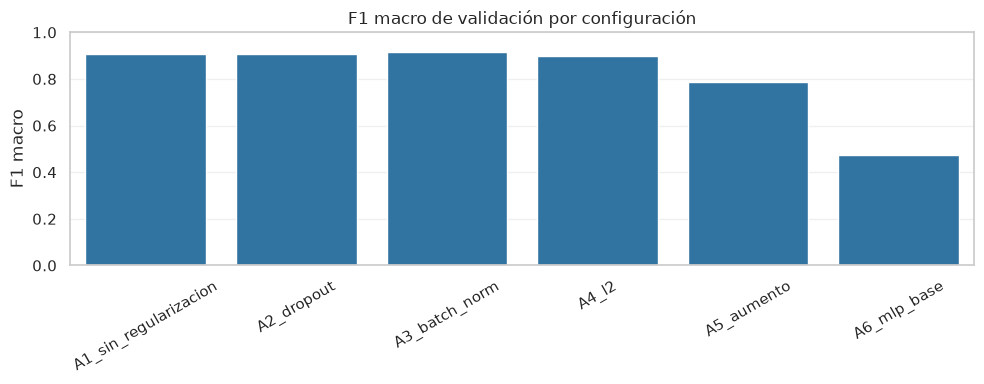

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=resultados_ablacion, x='experimento', y='f1_macro_val', color='#1f77b4', ax=ax)
ax.set_ylim(0, 1)
ax.set_title('F1 macro de validación por configuración')
ax.set_xlabel('')
ax.set_ylabel('F1 macro')
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'ablacion_f1.png', dpi=150)
plt.show()

### 6.1 Interpretación

- **Mejor configuración:** A3 con BatchNorm alcanzó un F1 macro de validación de 91,7%.
- **Sin regularización:** A1 obtuvo 90,8%, una diferencia de 1,0 punto porcentual.
- **Técnica que más aportó:** BatchNorm.
- **Brecha train-validación:** 6,5 puntos en la mejor variante.
- **Aumento de datos:** A5 bajó a 78,7%, por debajo de la CNN sin regularización.

## 7. Screening y búsqueda de hiperparámetros

El screening mueve un hiperparámetro a la vez alrededor de la mejor técnica de la ablación, BatchNorm. Revisamos tasa de aprendizaje, tamaño de lote, Dropout convolucional, Dropout denso, cantidad de filtros, L2 y aumento de datos. La configuración con mejor F1 macro de validación pasa a la búsqueda.

La búsqueda principal es Random Search. Elegimos este método porque cubre un espacio amplio con un presupuesto fijo, es reproducible y no requiere una librería adicional. Una grilla completa con siete hiperparámetros y tres valores por dimensión tendría 2.187 combinaciones. La validación cruzada de GridSearchCV multiplicaría el costo por cada fold y está pensada para estimadores de scikit-learn, no para un modelo Keras de este tamaño. La configuración con filtros grandes usa batch 32, el valor base, para no exceder la memoria.

In [16]:
config_regularizada = {
    'tipo': 'cnn',
    'filtros': (32, 64, 128),
    'neuronas': 128,
    'dropout_conv': 0.0,
    'dropout_dense': 0.0,
    'l2': 0.0,
    'usar_bn': True,
    'usar_aumento': False,
    'learning_rate': 1e-4,
    'batch_size': 32,
    'seed': SEED,
}

screening = [
    {**config_regularizada, 'nombre': 'B1_bn_base'},
    {**config_regularizada, 'nombre': 'B2_lr_1e-3', 'learning_rate': 1e-3},
    {**config_regularizada, 'nombre': 'B3_batch_64', 'batch_size': 64},
    {**config_regularizada, 'nombre': 'B4_dropout_conv_0.1', 'dropout_conv': 0.1},
    {**config_regularizada, 'nombre': 'B5_dropout_dense_0.2', 'dropout_dense': 0.2},
    {**config_regularizada, 'nombre': 'B6_filtros_64_128_256', 'filtros': (64, 128, 256)},
    {**config_regularizada, 'nombre': 'B7_l2_1e-5', 'l2': 1e-5},
    {**config_regularizada, 'nombre': 'B8_aumento', 'usar_aumento': True},
]

resultados_screening, mejor_screening = optimizar_modelo(df, screening, 'screening', epochs=EPOCHS)
display(resultados_screening.sort_values('f1_macro_val', ascending=False))

[1/8] B1_bn_base: F1 macro val 0.9151, accuracy val 0.9313, 13 épocas, 194.2 s


[2/8] B2_lr_1e-3: F1 macro val 0.9329, accuracy val 0.9413, 16 épocas, 222.3 s


[3/8] B3_batch_64: F1 macro val 0.9208, accuracy val 0.9375, 16 épocas, 210.7 s


[4/8] B4_dropout_conv_0.1: F1 macro val 0.6810, accuracy val 0.7683, 14 épocas, 204.9 s


[5/8] B5_dropout_dense_0.2: F1 macro val 0.9380, accuracy val 0.9494, 14 épocas, 195.8 s


[6/8] B6_filtros_64_128_256: F1 macro val 0.9370, accuracy val 0.9482, 13 épocas, 356.0 s


[7/8] B7_l2_1e-5: F1 macro val 0.9267, accuracy val 0.9413, 12 épocas, 206.9 s


[8/8] B8_aumento: F1 macro val 0.7545, accuracy val 0.7795, 11 épocas, 391.2 s


,bloque,experimento,tipo,filtros,neuronas,dropout_conv,dropout_dense,l2,usar_bn,usar_aumento,learning_rate,batch_size,accuracy_train,accuracy_val,f1_macro_val,brecha_val,parametros,epocas,tiempo_s
4,screening,B5_dropout_dense_0.2,cnn,32-64-128,128,0.0,0.2,0.00000,True,False,0.0001,32,0.999453,0.949407,0.938037,0.050047,4290378,14,195.786340
5,screening,B6_filtros_64_128_256,cnn,64-128-256,128,0.0,0.0,0.00000,True,False,0.0001,32,0.999610,0.948157,0.936971,0.051452,8763146,13,355.977237
1,screening,B2_lr_1e-3,cnn,32-64-128,128,0.0,0.0,0.00000,True,False,0.0010,32,0.995237,0.941287,0.932913,0.053951,4290378,16,222.268230
6,screening,B7_l2_1e-5,cnn,32-64-128,128,0.0,0.0,0.00001,True,False,0.0001,32,0.999688,0.941287,0.926684,0.058401,4290378,12,206.867972
2,screening,B3_batch_64,cnn,32-64-128,128,0.0,0.0,0.00000,True,False,0.0001,64,0.999141,0.937539,0.920844,0.061602,4290378,16,210.734093
0,screening,B1_bn_base,cnn,32-64-128,128,0.0,0.0,0.00000,True,False,0.0001,32,0.995003,0.931293,0.915110,0.063710,4290378,13,194.231480
7,screening,B8_aumento,cnn,32-64-128,128,0.0,0.0,0.00000,True,True,0.0001,32,0.953701,0.779513,0.754477,0.174188,4290378,11,391.194699
3,screening,B4_dropout_conv_0.1,cnn,32-64-128,128,0.1,0.0,0.00000,True,False,0.0001,32,0.995862,0.768270,0.681023,0.227592,4290378,14,204.894677


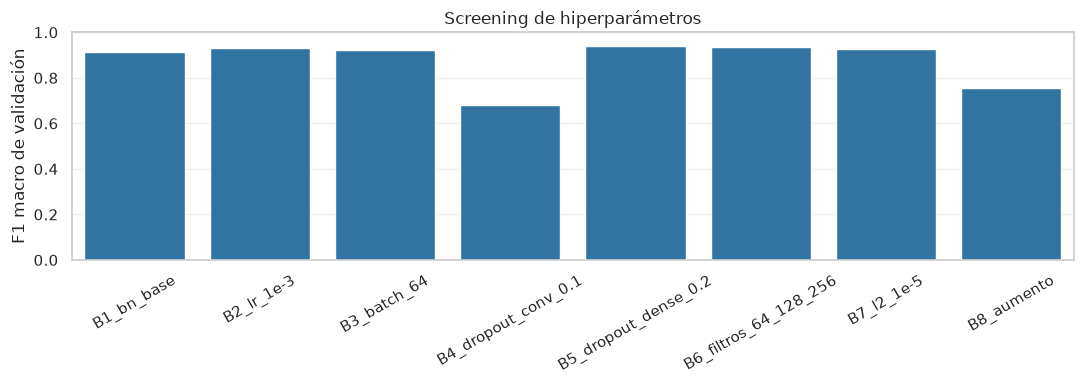

In [17]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=resultados_screening, x='experimento', y='f1_macro_val', color='#1f77b4', ax=ax)
ax.set_ylim(0, 1)
ax.set_title('Screening de hiperparámetros')
ax.set_xlabel('')
ax.set_ylabel('F1 macro de validación')
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'screening_f1.png', dpi=150)
plt.show()

### 7.1 Interpretación del screening

- **Mejor resultado:** B5 con Dropout denso de 0,2 alcanzó un F1 macro de validación de 93,8%.
- **Base regularizada:** B1 obtuvo 91,5%.
- **Cambio más dañino:** B4 con Dropout convolucional de 0,1 bajó a 68,1%.
- **Filtros grandes:** B6 llegó a 93,7% con casi el doble de parámetros.
- **Aumento de datos:** B8 bajó a 75,4%.

In [18]:
rng = np.random.default_rng(SEED)
configuraciones_busqueda = [{**mejor_screening, 'nombre': 'C1_mejor_screening', 'seed': SEED}]
while len(configuraciones_busqueda) < 8:
    config = {
        'tipo': 'cnn',
        'filtros': [(32, 64, 128), (64, 128, 256)][int(rng.integers(0, 2))],
        'neuronas': 128,
        'dropout_conv': float(rng.uniform(0.0, 0.2)),
        'dropout_dense': float(rng.uniform(0.0, 0.3)),
        'l2': float(rng.choice([0.0, 1e-5, 1e-4])),
        'usar_bn': True,
        'usar_aumento': bool(rng.random() < 0.25),
        'learning_rate': float(10 ** rng.uniform(-4.3, -3)),
        'batch_size': int(rng.choice([32, 64])),
        'seed': SEED,
    }
    if config['filtros'] == (64, 128, 256) and config['batch_size'] == 64:
        config['batch_size'] = 32
    config['nombre'] = f'C{len(configuraciones_busqueda) + 1}_aleatorio'
    configuraciones_busqueda.append(config)

tabla_busqueda = pd.DataFrame([
    {
        'nombre': c['nombre'],
        'filtros': '-'.join(map(str, c['filtros'])),
        'dropout_conv': round(c['dropout_conv'], 3),
        'dropout_dense': round(c['dropout_dense'], 3),
        'l2': round(c['l2'], 6),
        'usar_bn': c['usar_bn'],
        'usar_aumento': c['usar_aumento'],
        'learning_rate': round(c['learning_rate'], 6),
        'batch_size': c['batch_size'],
    }
    for c in configuraciones_busqueda
])
display(tabla_busqueda)

,nombre,filtros,dropout_conv,dropout_dense,l2,usar_bn,usar_aumento,learning_rate,batch_size
0,C1_mejor_screening,32-64-128,0.000,0.200,0.00000,True,False,0.000100,32
1,C2_aleatorio,32-64-128,0.088,0.258,0.00010,True,False,0.000066,64
2,C3_aleatorio,64-128-256,0.152,0.236,0.00001,True,False,0.000152,32
3,C4_aleatorio,32-64-128,0.129,0.247,0.00010,True,False,0.000099,32
4,C5_aleatorio,64-128-256,0.013,0.248,0.00000,True,False,0.000145,32
5,C6_aleatorio,32-64-128,0.179,0.234,0.00010,True,True,0.000203,32
6,C7_aleatorio,32-64-128,0.031,0.205,0.00010,True,False,0.000133,64
7,C8_aleatorio,64-128-256,0.094,0.057,0.00001,True,True,0.000208,32


In [19]:
resultados_busqueda, mejor_busqueda = optimizar_modelo(df, configuraciones_busqueda, 'busqueda', epochs=EPOCHS)
if mejor_busqueda['filtros'] == (64, 128, 256) and mejor_busqueda['batch_size'] == 64:
    mejor_busqueda = {**mejor_busqueda, 'batch_size': 32}
display(resultados_busqueda.sort_values('f1_macro_val', ascending=False))

[1/8] C1_mejor_screening: F1 macro val 0.9392, accuracy val 0.9513, 14 épocas, 260.4 s


[2/8] C2_aleatorio: F1 macro val 0.7060, accuracy val 0.7989, 16 épocas, 220.1 s


[3/8] C3_aleatorio: F1 macro val 0.8783, accuracy val 0.9119, 32 épocas, 885.4 s


[4/8] C4_aleatorio: F1 macro val 0.7809, accuracy val 0.8576, 28 épocas, 400.9 s


[5/8] C5_aleatorio: F1 macro val 0.9243, accuracy val 0.9394, 18 épocas, 499.0 s


[6/8] C6_aleatorio: F1 macro val 0.6989, accuracy val 0.7495, 12 épocas, 311.3 s


[7/8] C7_aleatorio: F1 macro val 0.8950, accuracy val 0.9188, 17 épocas, 234.1 s


[8/8] C8_aleatorio: F1 macro val 0.6988, accuracy val 0.7527, 8 épocas, 414.6 s


,bloque,experimento,tipo,filtros,neuronas,dropout_conv,dropout_dense,l2,usar_bn,usar_aumento,learning_rate,batch_size,accuracy_train,accuracy_val,f1_macro_val,brecha_val,parametros,epocas,tiempo_s
0,busqueda,C1_mejor_screening,cnn,32-64-128,128,0.000000,0.200000,0.00000,True,False,0.000100,32,0.998985,0.951280,0.939171,0.047705,4290378,14,260.385020
4,busqueda,C5_aleatorio,cnn,64-128-256,128,0.012763,0.248289,0.00000,True,False,0.000145,32,0.994613,0.939413,0.924294,0.055200,8763146,18,499.005262
6,busqueda,C7_aleatorio,cnn,32-64-128,128,0.030858,0.204915,0.00010,True,False,0.000133,64,0.998673,0.918801,0.895050,0.079872,4290378,17,234.097145
2,busqueda,C3_aleatorio,cnn,64-128-256,128,0.152228,0.235819,0.00001,True,False,0.000152,32,0.997267,0.911930,0.878279,0.085337,8763146,32,885.420061
3,busqueda,C4_aleatorio,cnn,32-64-128,128,0.128773,0.246828,0.00010,True,False,0.000099,32,0.992817,0.857589,0.780932,0.135228,4290378,28,400.863824
1,busqueda,C2_aleatorio,cnn,32-64-128,128,0.087776,0.257579,0.00010,True,False,0.000066,64,0.991021,0.798876,0.705962,0.192146,4290378,16,220.104643
5,busqueda,C6_aleatorio,cnn,32-64-128,128,0.178624,0.233515,0.00010,True,True,0.000203,32,0.921299,0.749532,0.698933,0.171768,4290378,12,311.310302
7,busqueda,C8_aleatorio,cnn,64-128-256,128,0.093911,0.056841,0.00001,True,True,0.000208,32,0.935899,0.752655,0.698819,0.183245,8763146,8,414.583558


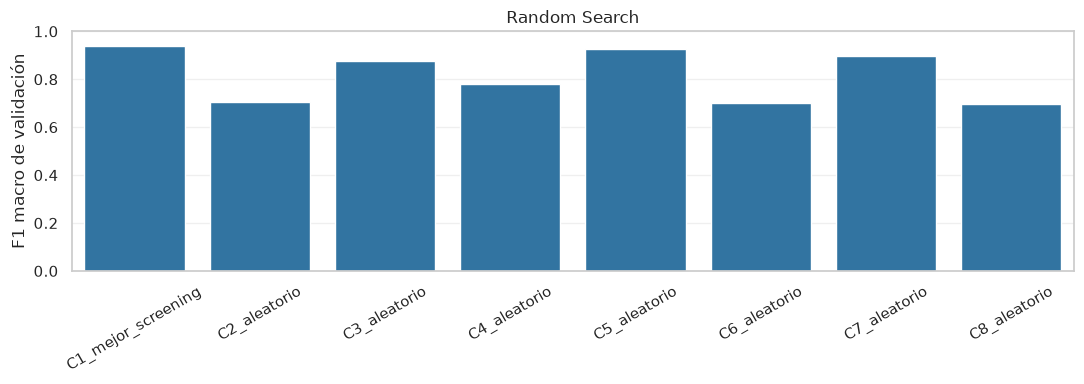

In [20]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=resultados_busqueda, x='experimento', y='f1_macro_val', color='#1f77b4', ax=ax)
ax.set_ylim(0, 1)
ax.set_title('Random Search')
ax.set_xlabel('')
ax.set_ylabel('F1 macro de validación')
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'busqueda_f1.png', dpi=150)
plt.show()

### 7.2 Interpretación de la búsqueda

- **Mejor configuración:** C1, la mejor del screening, alcanzó un F1 macro de validación de 93,9%.
- **Parámetros:** tasa de aprendizaje 1e-04, batch 32, Dropout convolucional 0,00 y Dropout denso 0,20.
- **Diferencia con el screening:** 0,1 punto porcentual.
- **Random Search:** ninguna configuración aleatoria superó a C1; la mejor fue C5 con 92,4%.

## 8. Entrenamiento final y evaluación

La configuración ganadora se entrena con tres semillas para reportar media y desviación. La semilla 42 se guarda como modelo final. El conjunto de test se usa solo para reportar el desempeño final, no para elegir la configuración.

La MLP se optimiza por separado. Comparamos la MLP de la EP2, una versión regularizada y una versión más liviana. Las dos últimas usan BatchNorm, L2 y Dropout, sin aumento, para centrar la comparación en la arquitectura. La mejor por F1 macro de validación se entrena con tres semillas y se guarda como modelo final.

Epoch 1/40


401/401 - 32s - 81ms/step - accuracy: 0.8107 - loss: 0.6319 - val_accuracy: 0.7495 - val_loss: 0.7321


Epoch 2/40


401/401 - 13s - 33ms/step - accuracy: 0.9324 - loss: 0.2670 - val_accuracy: 0.9001 - val_loss: 0.3127


Epoch 3/40


401/401 - 13s - 33ms/step - accuracy: 0.9689 - loss: 0.1533 - val_accuracy: 0.9113 - val_loss: 0.2746


... (18 outputs left out)

Epoch 13/40


401/401 - 13s - 32ms/step - accuracy: 0.9984 - loss: 0.0143 - val_accuracy: 0.9138 - val_loss: 0.2756


Epoch 14/40


401/401 - 13s - 33ms/step - accuracy: 0.9993 - loss: 0.0113 - val_accuracy: 0.9094 - val_loss: 0.3217


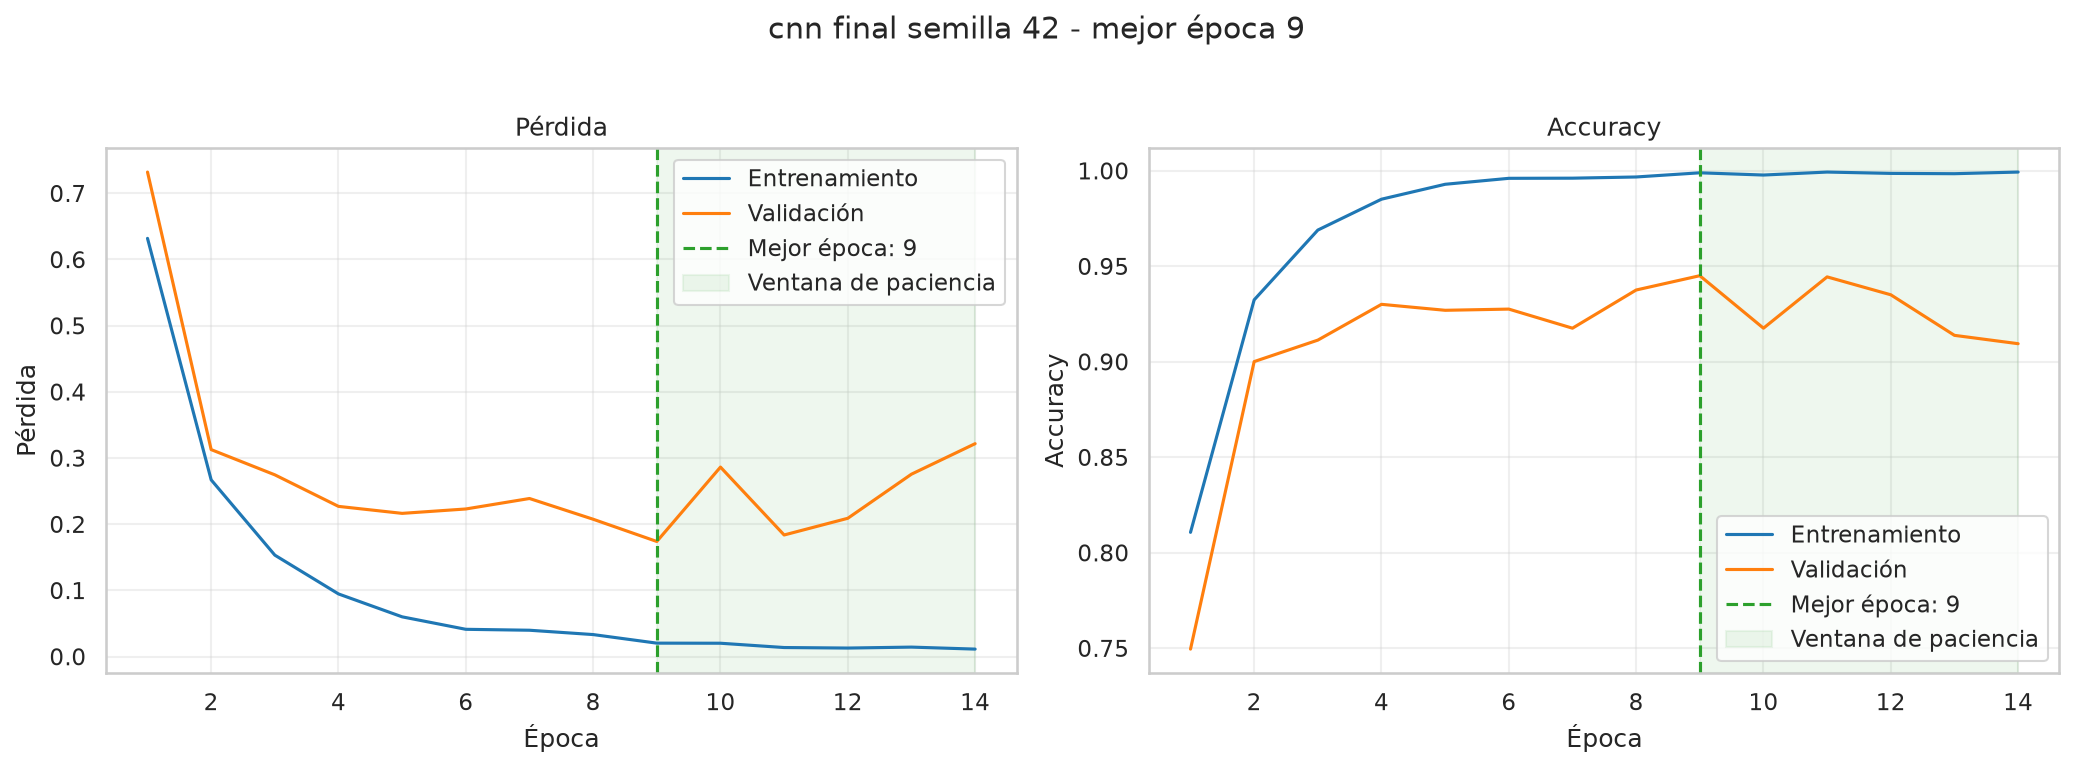

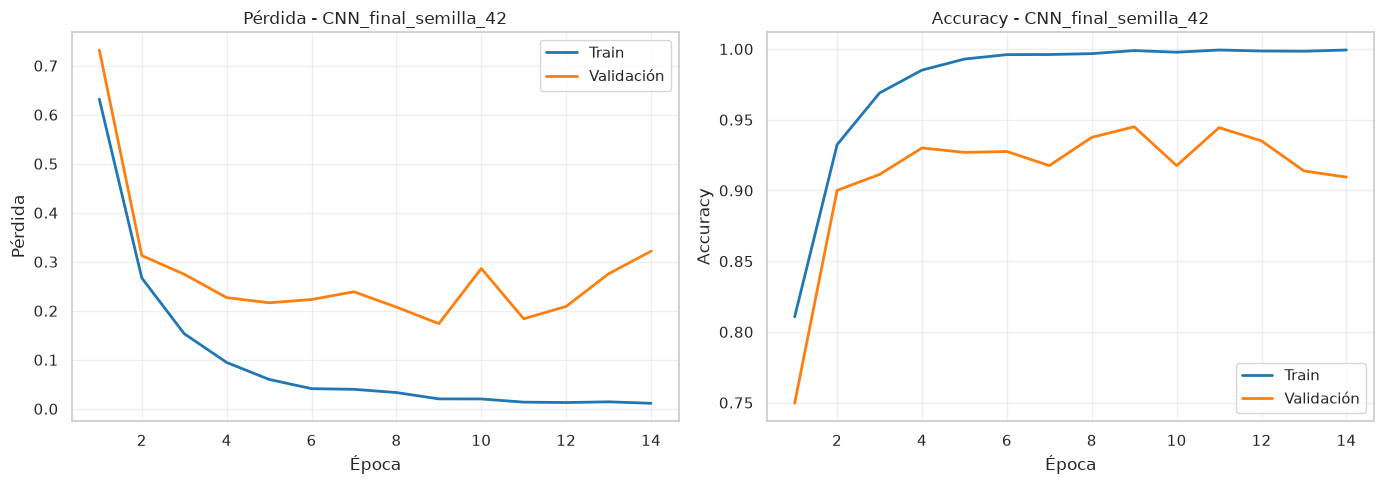

CNN_final semilla 42: accuracy 0.9444, F1 macro 0.9300, 14 épocas, 203.4 s


Epoch 1/40


401/401 - 27s - 68ms/step - accuracy: 0.8218 - loss: 0.5890 - val_accuracy: 0.6908 - val_loss: 0.8568


Epoch 2/40


401/401 - 13s - 33ms/step - accuracy: 0.9410 - loss: 0.2429 - val_accuracy: 0.9169 - val_loss: 0.2829


Epoch 3/40


... (48 outputs left out)

Epoch 13/40


401/401 - 13s - 33ms/step - accuracy: 0.9989 - loss: 0.0142 - val_accuracy: 0.9263 - val_loss: 0.2438


CNN_final semilla 44: accuracy 0.9413, F1 macro 0.9294, 13 épocas, 184.3 s


semilla,accuracy,f1_macro,accuracy_train,brecha_test,epocas,tiempo_s
42,0.9444,0.9300,0.9993,0.0549,14,203.4332
43,0.9395,0.9307,0.9992,0.0598,14,197.5341
44,0.9413,0.9294,0.9989,0.0576,13,184.2532


In [21]:
resultados_cnn, evaluacion_cnn, modelo_cnn = entrenar_final(df, mejor_busqueda, 'CNN_final', [42, 43, 44], 'cnn_ep3_final.keras')
display(resultados_cnn[['semilla', 'accuracy', 'f1_macro', 'accuracy_train', 'brecha_test', 'epocas', 'tiempo_s']])

In [22]:
reporte_cnn = evaluacion_cnn['reporte_df'].loc[clases, ['precision', 'recall', 'f1-score', 'support']]
reporte_cnn.insert(0, 'clase', [nombre_corto(clase) for clase in reporte_cnn.index])
display(reporte_cnn.sort_values('recall'))

,clase,precision,recall,f1-score,support
Tomato_Early_blight,Early blight,0.808081,0.800000,0.804020,100.0
Tomato_Late_blight,Late blight,0.910526,0.905759,0.908136,191.0
Tomato__Target_Spot,Target Spot,0.890411,0.921986,0.905923,141.0
Tomato_Spider_mites_Two_spotted_spider_mite,Spider mites Two spotted spider mite,0.950920,0.922619,0.936556,168.0
Tomato_Septoria_leaf_spot,Septoria leaf spot,0.970414,0.926554,0.947977,177.0
Tomato_Leaf_Mold,Leaf Mold,0.898990,0.936842,0.917526,95.0
Tomato__Tomato_mosaic_virus,mosaic virus,0.875000,0.945946,0.909091,37.0
Tomato_healthy,healthy,1.000000,0.987421,0.993671,159.0
Tomato__Tomato_YellowLeaf__Curl_Virus,YellowLeaf Curl Virus,0.981481,0.990654,0.986047,321.0
Tomato_Bacterial_spot,Bacterial spot,0.986047,0.995305,0.990654,213.0


### 8.1 Interpretación de la CNN final

- **Test:** 94,4% de accuracy y 93,0% de F1 macro.
- **Semillas:** F1 macro medio de 93,0% con desviación de 0,06 puntos.
- **Parámetros:** 4.290.378.
- **Mejor época:** 9 de 14, con 99,89% de accuracy en train, 94,50% en validación y 94,44% en test.
- **Brecha train-test:** 5,4 puntos en la mejor época.
- **Pérdida:** la curva de pérdida se separa más que la accuracy porque mide confianza.

In [23]:
config_mlp = {
    'tipo': 'mlp',
    'filtros': (),
    'capas_mlp': (512, 256, 128),
    'dropout_dense': 0.2,
    'l2': 0.0,
    'usar_bn': False,
    'usar_aumento': False,
    'learning_rate': 1e-4,
    'batch_size': 32,
    'seed': SEED,
}

configuraciones_mlp = [
    {**config_mlp, 'nombre': 'E1_mlp_ep2'},
    {**config_mlp, 'nombre': 'E2_mlp_regularizada', 'dropout_dense': 0.3, 'l2': 1e-4, 'usar_bn': True, 'usar_aumento': False},
    {**config_mlp, 'nombre': 'E3_mlp_ligera', 'capas_mlp': (256, 128, 64), 'dropout_dense': 0.3, 'l2': 1e-4, 'usar_bn': True, 'usar_aumento': False},
]

resultados_mlp_busqueda, mejor_mlp = optimizar_modelo(df, configuraciones_mlp, 'mlp', epochs=30)
display(resultados_mlp_busqueda.sort_values('f1_macro_val', ascending=False))

[1/3] E1_mlp_ep2: F1 macro val 0.4752, accuracy val 0.5996, 24 épocas, 122.3 s


[2/3] E2_mlp_regularizada: F1 macro val 0.6190, accuracy val 0.6446, 12 épocas, 72.1 s


[3/3] E3_mlp_ligera: F1 macro val 0.6661, accuracy val 0.7008, 22 épocas, 96.3 s


,bloque,experimento,tipo,filtros,neuronas,dropout_conv,dropout_dense,l2,usar_bn,usar_aumento,learning_rate,batch_size,accuracy_train,accuracy_val,f1_macro_val,brecha_val,parametros,epocas,tiempo_s
2,mlp,E3_mlp_ligera,mlp,,128,0.0,0.3,0.0001,True,False,0.0001,32,0.877733,0.700812,0.666084,0.176921,12626762,22,96.301833
1,mlp,E2_mlp_regularizada,mlp,,128,0.0,0.3,0.0001,True,False,0.0001,32,0.859229,0.644597,0.619046,0.214631,25335434,12,72.097438
0,mlp,E1_mlp_ep2,mlp,,128,0.0,0.2,0.0000,False,False,0.0001,32,0.533573,0.599625,0.475171,-0.066052,25331850,24,122.336165


Epoch 1/40


401/401 - 15s - 38ms/step - accuracy: 0.3823 - loss: 1.9057 - val_accuracy: 0.3929 - val_loss: 1.8758


Epoch 2/40


401/401 - 4s - 9ms/step - accuracy: 0.5623 - loss: 1.4647 - val_accuracy: 0.5284 - val_loss: 1.4866


Epoch 3/40


401/401 - 3s - 9ms/step - accuracy: 0.6272 - loss: 1.2839 - val_accuracy: 0.6177 - val_loss: 1.2726


... (34 outputs left out)

Epoch 21/40


401/401 - 4s - 9ms/step - accuracy: 0.8699 - loss: 0.5350 - val_accuracy: 0.5340 - val_loss: 1.7750


Epoch 22/40


401/401 - 3s - 9ms/step - accuracy: 0.8777 - loss: 0.5056 - val_accuracy: 0.5228 - val_loss: 1.9558


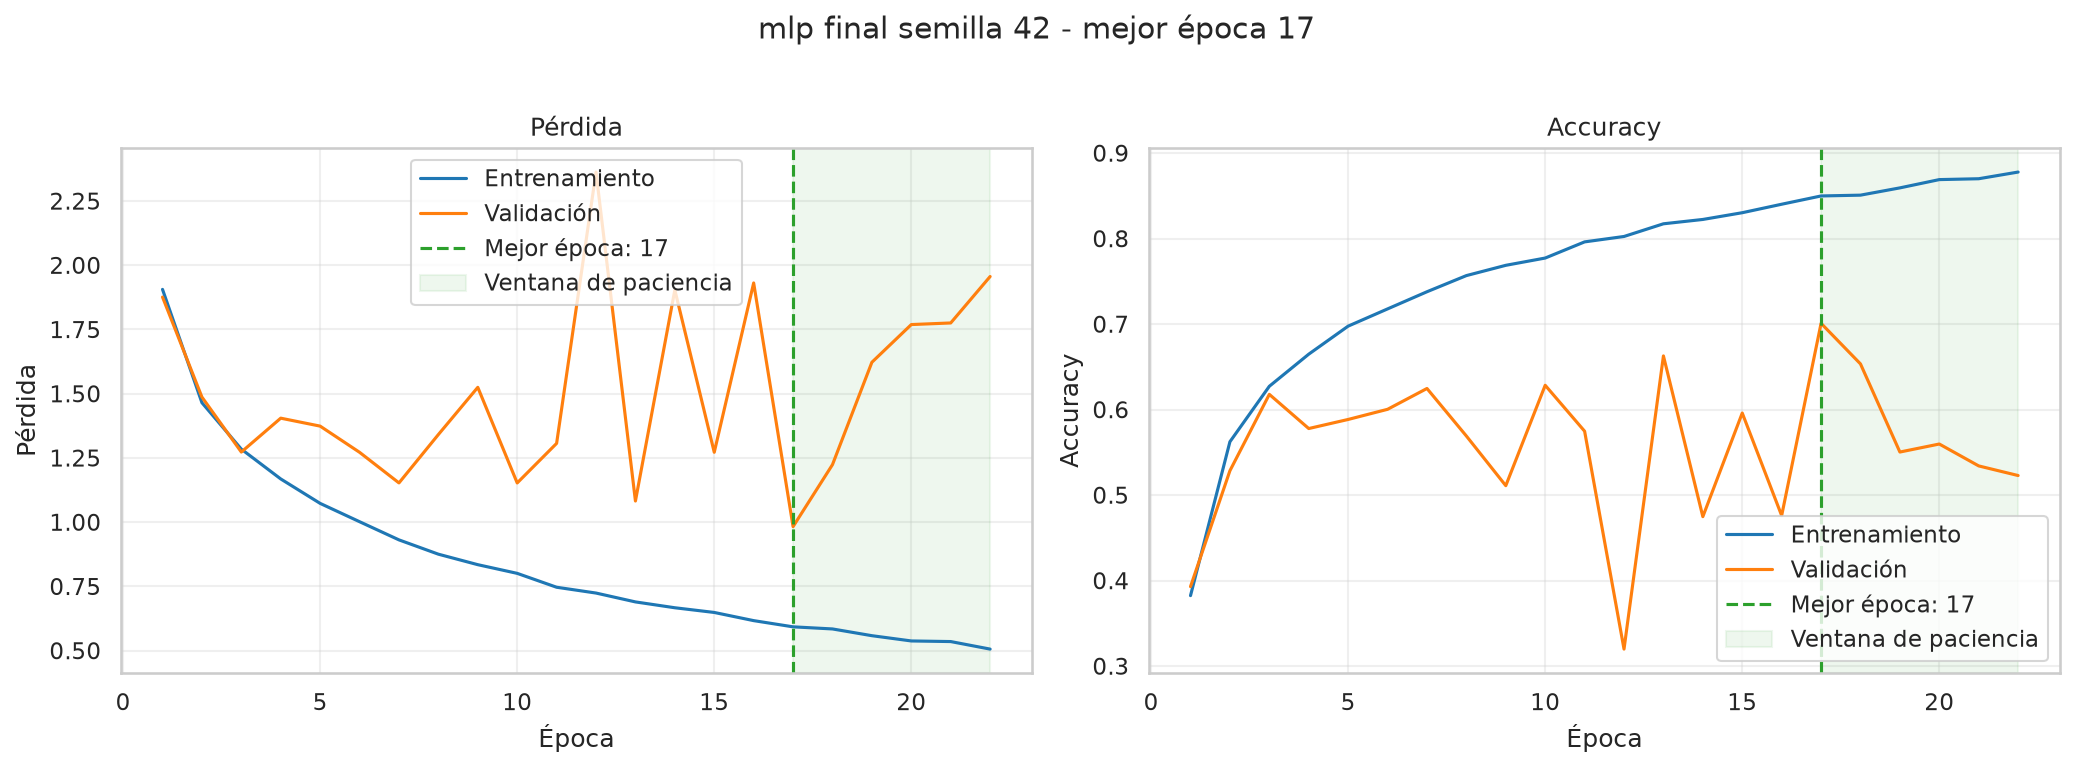

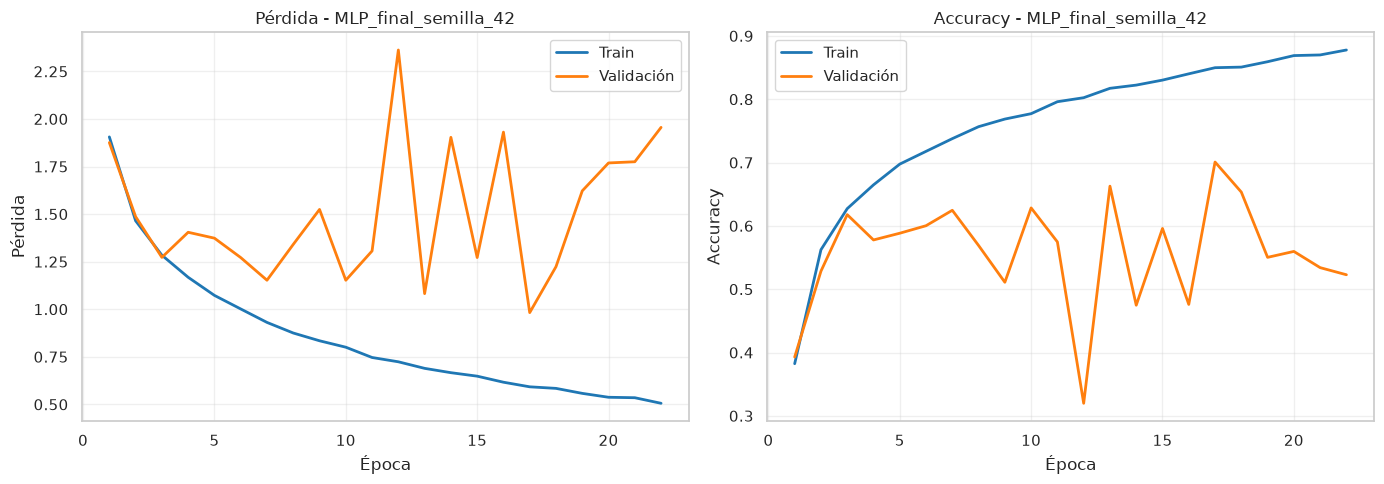

MLP_final semilla 42: accuracy 0.6923, F1 macro 0.6514, 22 épocas, 90.6 s


Epoch 1/40


401/401 - 17s - 42ms/step - accuracy: 0.4278 - loss: 1.8225 - val_accuracy: 0.3791 - val_loss: 2.0843


Epoch 2/40


401/401 - 4s - 10ms/step - accuracy: 0.5823 - loss: 1.3975 - val_accuracy: 0.4666 - val_loss: 1.6440


Epoch 3/40


... (46 outputs left out)

Epoch 11/40


401/401 - 4s - 9ms/step - accuracy: 0.7902 - loss: 0.7672 - val_accuracy: 0.4947 - val_loss: 1.8924


MLP_final semilla 44: accuracy 0.5799, F1 macro 0.5162, 11 épocas, 53.6 s


semilla,accuracy,f1_macro,accuracy_train,brecha_test,epocas,tiempo_s
42,0.6923,0.6514,0.8777,0.1855,22,90.6249
43,0.6323,0.5684,0.8275,0.1951,15,68.8327
44,0.5799,0.5162,0.7902,0.2103,11,53.6391


In [24]:
resultados_mlp, evaluacion_mlp, modelo_mlp = entrenar_final(df, mejor_mlp, 'MLP_final', [42, 43, 44], 'mlp_ep3_final.keras')
display(resultados_mlp[['semilla', 'accuracy', 'f1_macro', 'accuracy_train', 'brecha_test', 'epocas', 'tiempo_s']])

In [25]:
reporte_mlp = evaluacion_mlp['reporte_df'].loc[clases, ['precision', 'recall', 'f1-score', 'support']]
reporte_mlp.insert(0, 'clase', [nombre_corto(clase) for clase in reporte_mlp.index])
display(reporte_mlp.sort_values('recall'))

,clase,precision,recall,f1-score,support
Tomato_Early_blight,Early blight,0.306818,0.270000,0.287234,100.0
Tomato_healthy,healthy,0.957143,0.421384,0.585153,159.0
Tomato__Target_Spot,Target Spot,0.825000,0.468085,0.597285,141.0
Tomato_Septoria_leaf_spot,Septoria leaf spot,0.832061,0.615819,0.707792,177.0
Tomato_Leaf_Mold,Leaf Mold,0.845070,0.631579,0.722892,95.0
Tomato_Spider_mites_Two_spotted_spider_mite,Spider mites Two spotted spider mite,0.814815,0.654762,0.726073,168.0
Tomato_Bacterial_spot,Bacterial spot,0.816327,0.751174,0.782396,213.0
Tomato__Tomato_mosaic_virus,mosaic virus,0.485294,0.891892,0.628571,37.0
Tomato_Late_blight,Late blight,0.434243,0.916230,0.589226,191.0
Tomato__Tomato_YellowLeaf__Curl_Virus,YellowLeaf Curl Virus,0.838889,0.940810,0.886931,321.0


### 8.2 Interpretación de la MLP final

- **Test:** 69,2% de accuracy y 65,1% de F1 macro.
- **Semillas:** F1 macro medio de 57,9% con desviación de 6,8 puntos.
- **Parámetros:** 12.626.762.
- **Mejor época:** 17 de 22, con 84,98% de accuracy en train, 70,08% en validación y 69,23% en test.
- **Brecha train-test:** 15,7 puntos en la mejor época y 18,5 en la última.
- **Sobreajuste:** la curva es más inestable que la de la CNN.

In [26]:
filas = []
for nombre, resultados, evaluacion, modelo in [
    ('CNN final', resultados_cnn, evaluacion_cnn, modelo_cnn),
    ('MLP final', resultados_mlp, evaluacion_mlp, modelo_mlp),
]:
    filas.append({
        'modelo': nombre,
        'accuracy': evaluacion['metricas']['accuracy'],
        'balanced_accuracy': evaluacion['metricas']['balanced_accuracy'],
        'precision_macro': evaluacion['metricas']['precision_macro'],
        'recall_macro': evaluacion['metricas']['recall_macro'],
        'f1_macro': evaluacion['metricas']['f1_macro'],
        'f1_weighted': evaluacion['metricas']['f1_weighted'],
        'roc_auc': evaluacion['metricas']['roc_auc'],
        'parametros': modelo.count_params(),
        'brecha_test': resultados.loc[resultados['semilla'] == 42, 'brecha_test'].iloc[0],
        'tiempo_entrenamiento_s': resultados.loc[resultados['semilla'] == 42, 'tiempo_s'].iloc[0],
        'tiempo_inferencia_ms': medir_inferencia(modelo, test_ds),
        'f1_macro_media': resultados['f1_macro'].mean(),
        'f1_macro_desviacion': resultados['f1_macro'].std(),
    })
comparacion = pd.DataFrame(filas)
display(comparacion)
comparacion.to_csv(MODELS_DIR / 'comparacion_final.csv', index=False)

modelo,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc,parametros,brecha_test,tiempo_entrenamiento_s,tiempo_inferencia_ms,f1_macro_media,f1_macro_desviacion
CNN final,0.9444,0.9333,0.9272,0.9333,0.9300,0.9445,0.9973,4290378,0.0549,203.4332,6.1660,0.9300,0.0006
MLP final,0.6923,0.6562,0.7156,0.6562,0.6514,0.6923,0.9635,12626762,0.1855,90.6249,4.6262,0.5786,0.0682


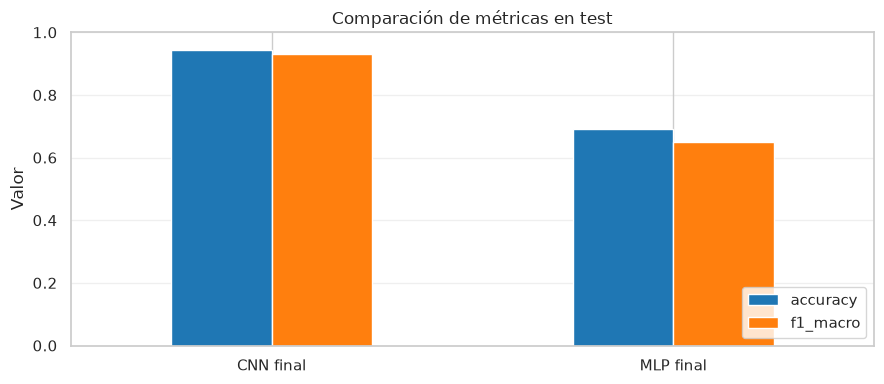

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
comparacion.set_index('modelo')[['accuracy', 'f1_macro']].plot(kind='bar', ax=ax, color=['#1f77b4', '#ff7f0e'])
ax.set_ylim(0, 1)
ax.set_title('Comparación de métricas en test')
ax.set_xlabel('')
ax.set_ylabel('Valor')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'comparacion_modelos.png', dpi=150)
plt.show()

### 8.3 Interpretación de la comparación

- **F1 macro:** la CNN superó a la MLP por 27,9 puntos en test.
- **Parámetros:** la CNN usa 2,9 veces menos.
- **Entrenamiento:** 3,4 minutos para la CNN y 1,5 para la MLP.
- **Inferencia:** 6,2 ms por imagen en la CNN y 4,6 ms en la MLP.
- **Recomendación:** CNN por desempeño y generalización; la MLP conserva ventaja en simplicidad y tiempo de inferencia.

## 9. Auditoría de sesgos

La auditoría revisa tres frentes:

- **Sesgo de entrada:** desbalance y representación de clases.
- **Sesgo de sistema:** desempeño por clase, brecha entre métricas macro y ponderadas y tipos de error.
- **Sesgo de aplicación:** uso fuera del laboratorio y costo de un falso negativo.

No buscamos demostrar que el modelo es justo. Buscamos identificar dónde puede fallar y qué medidas reducirían el riesgo.

In [28]:
auditoria_clases = reporte_cnn.copy()
auditoria_clases['brecha_contra_mejor'] = auditoria_clases['recall'].max() - auditoria_clases['recall']
display(auditoria_clases.sort_values('recall'))
print('F1 macro:', round(evaluacion_cnn['metricas']['f1_macro'], 4))
print('F1 ponderado:', round(evaluacion_cnn['metricas']['f1_weighted'], 4))
print('Brecha macro y ponderado:', round(evaluacion_cnn['metricas']['f1_weighted'] - evaluacion_cnn['metricas']['f1_macro'], 4))

,clase,precision,recall,f1-score,support,brecha_contra_mejor
Tomato_Early_blight,Early blight,0.808081,0.800000,0.804020,100.0,0.195305
Tomato_Late_blight,Late blight,0.910526,0.905759,0.908136,191.0,0.089546
Tomato__Target_Spot,Target Spot,0.890411,0.921986,0.905923,141.0,0.073319
Tomato_Spider_mites_Two_spotted_spider_mite,Spider mites Two spotted spider mite,0.950920,0.922619,0.936556,168.0,0.072686
Tomato_Septoria_leaf_spot,Septoria leaf spot,0.970414,0.926554,0.947977,177.0,0.068751
Tomato_Leaf_Mold,Leaf Mold,0.898990,0.936842,0.917526,95.0,0.058463
Tomato__Tomato_mosaic_virus,mosaic virus,0.875000,0.945946,0.909091,37.0,0.049359
Tomato_healthy,healthy,1.000000,0.987421,0.993671,159.0,0.007884
Tomato__Tomato_YellowLeaf__Curl_Virus,YellowLeaf Curl Virus,0.981481,0.990654,0.986047,321.0,0.004651
Tomato_Bacterial_spot,Bacterial spot,0.986047,0.995305,0.990654,213.0,0.000000


F1 macro: 0.93
F1 ponderado: 0.9445
Brecha macro y ponderado: 0.0145


In [29]:
matriz = evaluacion_cnn['cm']
indice_healthy = clases.index('Tomato_healthy')
falsos_negativos = int(matriz[indice_healthy].sum() - matriz[indice_healthy, indice_healthy])
print('Casos sanos mal clasificados como enfermedad:', falsos_negativos)
print('Total de casos sanos en test:', int(matriz[indice_healthy].sum()))

Casos sanos mal clasificados como enfermedad: 2
Total de casos sanos en test: 159


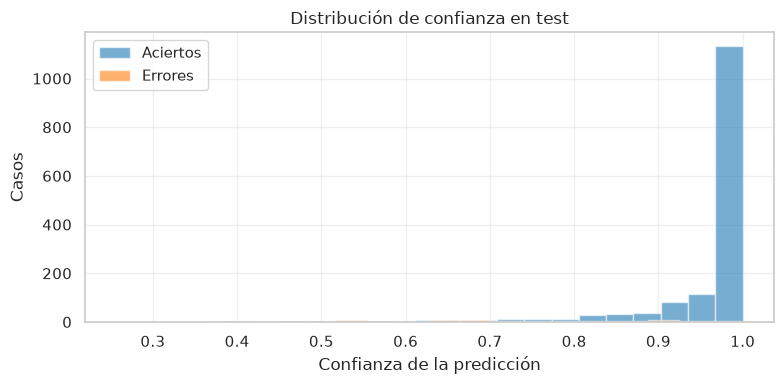

Confianza media en aciertos: 0.9591
Confianza media en errores: 0.6728


In [30]:
confianza = evaluacion_cnn['y_prob'].max(axis=1)
aciertos = evaluacion_cnn['y_pred'] == evaluacion_cnn['y_true']
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(confianza[aciertos], bins=20, alpha=0.6, label='Aciertos', color='#1f77b4')
ax.hist(confianza[~aciertos], bins=20, alpha=0.6, label='Errores', color='#ff7f0e')
ax.set_xlabel('Confianza de la predicción')
ax.set_ylabel('Casos')
ax.set_title('Distribución de confianza en test')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'confianza_cnn.png', dpi=150)
plt.show()
print('Confianza media en aciertos:', round(float(confianza[aciertos].mean()), 4))
print('Confianza media en errores:', round(float(confianza[~aciertos].mean()), 4))

In [31]:
hashes = df['abs_path'].map(lambda ruta: hashlib.md5(Path(ruta).read_bytes()).hexdigest())
print('Imágenes duplicadas exactas:', int(hashes.duplicated().sum()))
print('Clases con menos de 400 imágenes en total:', resumen[resumen['total'] < 400].index.tolist())

Imágenes duplicadas exactas: 14
Clases con menos de 400 imágenes en total: ['Tomato__Tomato_mosaic_virus']


In [32]:
estres = prueba_estres(modelo_cnn, df, 'cnn')
display(estres)
estres.to_csv(MODELS_DIR / 'prueba_estres.csv', index=False)

,transformacion,accuracy,f1_macro
0,brillo_bajo,0.794632,0.779356
1,brillo_alto,0.883271,0.865224
2,contraste_bajo,0.729713,0.677151
3,contraste_alto,0.841448,0.826032


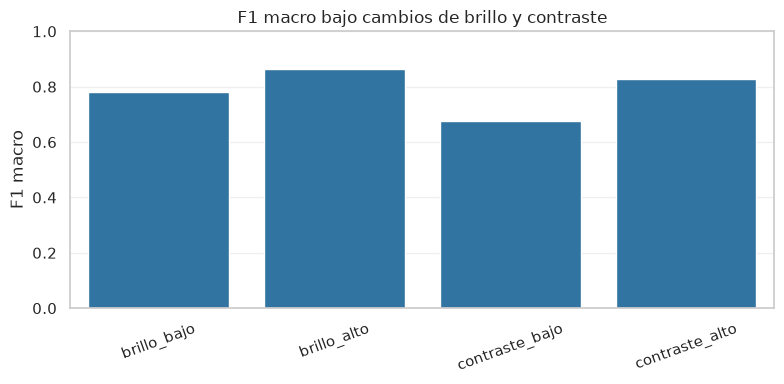

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=estres, x='transformacion', y='f1_macro', color='#1f77b4', ax=ax)
ax.set_ylim(0, 1)
ax.set_title('F1 macro bajo cambios de brillo y contraste')
ax.set_xlabel('')
ax.set_ylabel('F1 macro')
ax.tick_params(axis='x', rotation=20)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'prueba_estres.png', dpi=150)
plt.show()

### 9.1 Interpretación

- **F1 macro y ponderado:** la diferencia es de 1,5 puntos.
- **Clase sana:** 2 falsos negativos.
- **Menor sensibilidad:** Early blight, Late blight y Target Spot.
- **Prueba de estrés:** el F1 macro bajó a 67,7% con contraste bajo.
- **Iluminación:** el modelo es sensible a cambios de brillo y contraste.

## 10. Explicabilidad

Usamos Grad-CAM en la CNN y LIME en la MLP. Grad-CAM muestra qué regiones de la imagen activan la clase predicha. LIME muestra qué superpíxeles empujan la predicción. Las dos técnicas son locales y no prueban causalidad, pero ayudan a detectar atajos y errores.

Revisamos aciertos y errores. Un mapa que mira el fondo o el borde de la hoja es una señal de alerta. Un mapa que se concentra en la lesión es una señal de apoyo, no una garantía.

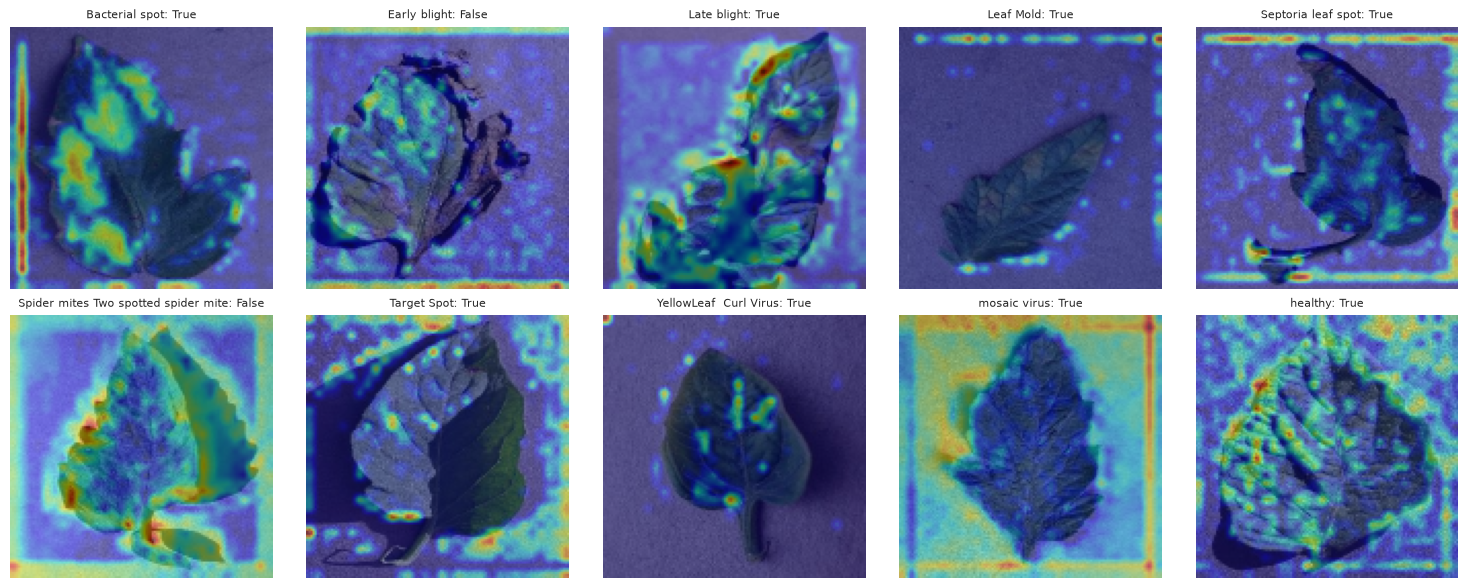

In [34]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, clase in zip(axes.ravel(), clases):
    fila = df[(df['label'] == clase) & (df['split'] == 'test')].iloc[0]
    imagen, _ = cargar_imagen(fila['abs_path'], fila['y'])
    imagen = tf.expand_dims(imagen, 0)
    prediccion = int(tf.argmax(modelo_cnn.predict(imagen, verbose=0), axis=1)[0])
    heatmap = gradcam(modelo_cnn, imagen, prediccion)
    ax.imshow(superponer_gradcam(imagen[0].numpy(), heatmap))
    ax.set_title(f'{nombre_corto(clase)}: {prediccion == fila["y"]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'gradcam_clases.png', dpi=150)
plt.show()

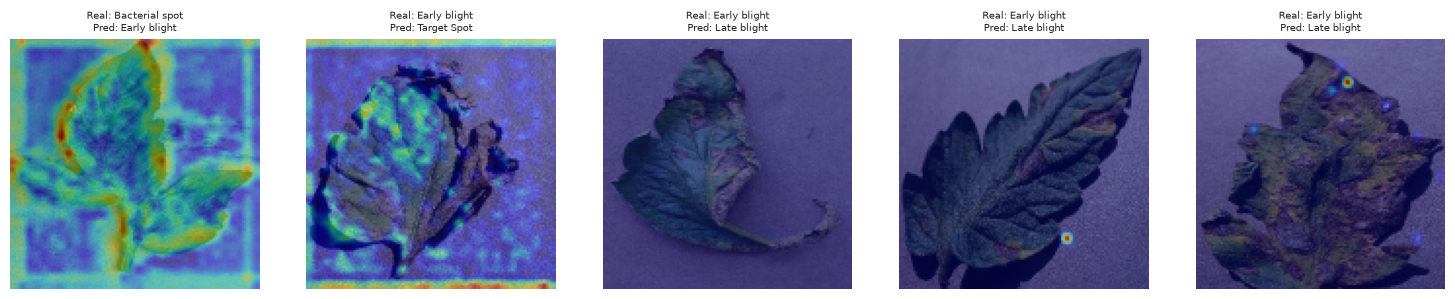

In [35]:
test_df = df[df['split'] == 'test'].reset_index(drop=True)
errores = np.where(evaluacion_cnn['y_pred'] != evaluacion_cnn['y_true'])[0]
seleccion = errores[:5]
fig, axes = plt.subplots(1, max(len(seleccion), 1), figsize=(15, 3))
for ax, indice in zip(np.atleast_1d(axes), seleccion):
    fila = test_df.iloc[indice]
    imagen, _ = cargar_imagen(fila['abs_path'], fila['y'])
    imagen = tf.expand_dims(imagen, 0)
    prediccion = int(evaluacion_cnn['y_pred'][indice])
    heatmap = gradcam(modelo_cnn, imagen, prediccion)
    ax.imshow(superponer_gradcam(imagen[0].numpy(), heatmap))
    ax.set_title(f'Real: {nombre_corto(fila["label"])}\nPred: {nombre_corto(clases[prediccion])}', fontsize=7)
    ax.axis('off')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'gradcam_errores.png', dpi=150)
plt.show()

  0%|          | 0/200 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step

... (113 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step


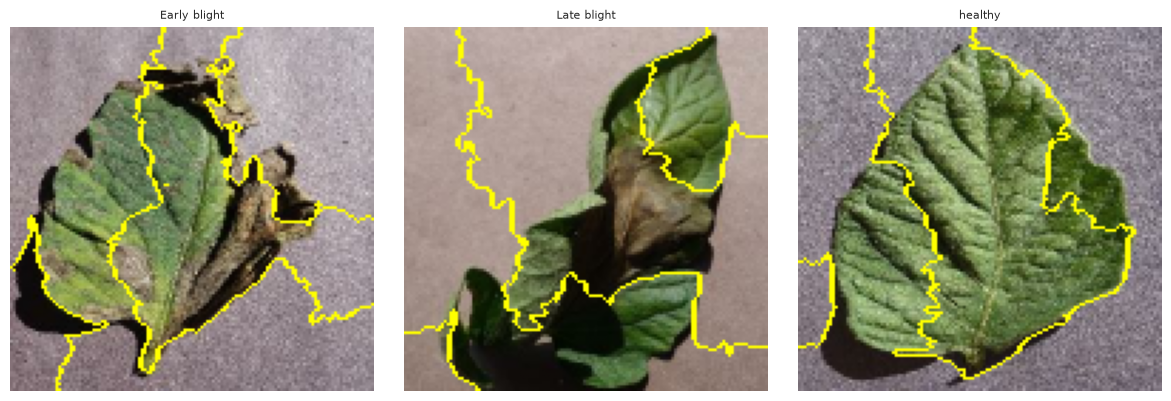

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, clase in zip(axes, ['Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_healthy']):
    fila = df[(df['label'] == clase) & (df['split'] == 'test')].iloc[0]
    imagen, _ = cargar_imagen(fila['abs_path'], fila['y'])
    imagen = tf.expand_dims(imagen, 0)
    temp, _ = explicar_lime(modelo_mlp, imagen, num_samples=200)
    ax.imshow(temp)
    ax.set_title(nombre_corto(clase), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'lime_mlp.png', dpi=150)
plt.show()

### 10.1 Interpretación de la explicabilidad

Grad-CAM permite revisar las regiones que sostienen la predicción de la CNN. En los ejemplos revisados, el mapa se concentra en la hoja y, en varios casos, en la zona de la lesión. En los errores, la atención se dispersa hacia el fondo o hacia tejido sano. LIME en la MLP resalta regiones más fragmentadas, consistente con la pérdida de estructura espacial al aplanar la imagen. Las dos técnicas se usan como auditoría cualitativa y no como prueba de causalidad.

## 11. Conclusiones

- **Desempeño:** la CNN superó a la MLP en exactitud, F1 macro y estabilidad entre semillas.
- **Regularización:** BatchNorm fue la técnica que más aportó. El aumento de datos bajó el F1 macro en este conjunto.
- **Búsqueda:** Random Search confirmó una configuración simple, con Dropout denso de 0,2 y sin aumento.
- **Brecha:** 5,4 puntos en la CNN y 15,7 en la MLP. La MLP sobreajusta más.
- **Alcance:** el modelo es académico, no es un diagnóstico autónomo y falta validación con imágenes de campo.

In [37]:
experimentos = pd.concat([
    resultados_ablacion,
    resultados_screening,
    resultados_busqueda,
    resultados_cnn.assign(bloque='final_cnn'),
    resultados_mlp_busqueda.assign(bloque='busqueda_mlp'),
    resultados_mlp.assign(bloque='final_mlp'),
], ignore_index=True)
experimentos.to_csv(MODELS_DIR / 'experimentos.csv', index=False)



metricas_finales = {
    'cnn': {
        'config': mejor_busqueda,
        'test': evaluacion_cnn['metricas'],
        'semillas': resultados_cnn[['semilla', 'accuracy', 'f1_macro']].to_dict(orient='records'),
        'parametros': int(modelo_cnn.count_params()),
    },
    'mlp': {
        'config': mejor_mlp,
        'test': evaluacion_mlp['metricas'],
        'semillas': resultados_mlp[['semilla', 'accuracy', 'f1_macro']].to_dict(orient='records'),
        'parametros': int(modelo_mlp.count_params()),
    },
    'comparacion': comparacion.to_dict(orient='records'),
}
with open(MODELS_DIR / 'metricas_finales.json', 'w', encoding='utf-8') as archivo:
    json.dump(metricas_finales, archivo, indent=2, ensure_ascii=False, default=float)

print('Archivos generados')
for ruta in [MODELS_DIR / 'experimentos.csv', MODELS_DIR / 'metricas_finales.json', MODELS_DIR / 'comparacion_final.csv', MODELS_DIR / 'cnn_ep3_final.keras', MODELS_DIR / 'mlp_ep3_final.keras']:
    print(ruta.relative_to(RAIZ), round(ruta.stat().st_size / 1e6, 2), 'MB')

Archivos generados
models/experimentos.csv 0.01 MB
models/metricas_finales.json 0.0 MB
models/comparacion_final.csv 0.0 MB
models/cnn_ep3_final.keras 17.24 MB
models/mlp_ep3_final.keras 50.56 MB
